# Nudge Problem: Recurrent Neural Network

This notebook follows the main ideas of **Week 6** (sequence data, the hidden state, backpropagation through time, vanishing gradients, clipping) and answers the review session's **Vignette E** (answer key p21): logistic regression on word counts throws away order, so read the visit **in order**.

1. Turn each visit into a sequence of word ids, padded to the same length.
2. Build a plain RNN with exactly the hidden-state formula of Week 6 s28, and a GRU (a gated RNN, named in Week 6 s31).
3. Train both with the **same loop** as logistic regression in `02_baselines`.
4. Score them **once** on the same test shoppers, with the same cut-off rule and money table.
5. Check whether order really matters: by visit length, and by shuffling the clicks of each visit.

**Owner:** TBD (Comparison role)

## 0. One-time setup
The project's `.venv` already has everything. On a new computer:

In [1]:
# %pip install -r ../requirements.txt

## 1. Import the packages
- `torch`, `torch.nn`: `nn.Embedding`, `nn.RNN`, `nn.GRU`, `nn.Linear`
- `pack_padded_sequence`: lets the RNN skip the padding at the end of short visits (Week 8 s20: "padding is masked out")
- `nudge.train`, `nudge.evaluate`: the same helpers as `02_baselines`

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence

from nudge.contract import VOCAB
from nudge.train import (SEED, BLOCK_SIZE, VOCAB_SIZE, set_seed, visits_to_ids, word_counts, make_loader,
                         train_model, predict_proba, plot_history)
from nudge.evaluate import pick_cutoff, quality, money, bootstrap

set_seed(SEED)
torch.set_num_threads(4)                 # keep the Mac responsive
device = torch.device("cpu")             # measured: 10x faster than the Apple GPU for this small model, and repeatable
print("device:", device)

device: cpu


## 2. Load the visits
The same visits and the same split **by shopper** as in `02_baselines`, so every model is compared on the same test shoppers.

In [3]:
visits = pd.read_parquet("../data/raw/visits_10pct.parquet")
train_df = visits[visits["split"] == "train"].reset_index(drop=True)
val_df = visits[visits["split"] == "valid"].reset_index(drop=True)
test_df = visits[visits["split"] == "test"].reset_index(drop=True)
y = {"train": train_df["label"].to_numpy(), "val": val_df["label"].to_numpy(), "test": test_df["label"].to_numpy()}
for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:10s} {len(df):8,} visits | {df['label'].mean():.1%} come back and buy")

train       933,419 visits | 8.7% come back and buy
validation  115,544 visits | 8.6% come back and buy
test        117,531 visits | 8.6% come back and buy


## 3. A visit as a sequence
Each visit becomes a row of `BLOCK_SIZE = 64` word ids: $x_1, \dots, x_T$ (Week 6 s20). Short visits are padded with 0 (`<pad>`) at the end; the rare visits longer than 64 words keep their first word (`new`/`returning`) and their last 63 clicks.
This time we keep the **order**: the RNN reads $x_1$, then $x_2$, and so on.

In [4]:
X = {name: visits_to_ids(df["tokens"]) for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]}
lengths = (X["test"] != 0).sum(axis=1)
print("shape of the test matrix:", X["test"].shape)
print("words per visit: median", int(np.median(lengths)), "| 90th percentile", int(np.percentile(lengths, 90)), "| max", lengths.max())
print("example:", list(test_df["tokens"][3]), "->", X["test"][3][:8], "...")

shape of the test matrix: (117531, 64)
words per visit: median 4 | 90th percentile 15 | max 64
example: ['returning', 'view_expensive_start', 'view_expensive_long', 'view_expensive_quick', 'view_expensive_again_normal', 'view_expensive_quick', 'view_expensive_again_normal', 'view_expensive_again_quick', 'view_expensive_normal', 'view_expensive_again_quick', 'view_expensive_again_away', 'view_mid_long', 'view_cheap_long', 'view_cheap_normal', 'view_cheap_long', 'view_cheap_again_long', 'view_cheap_again_quick'] -> [ 2 23 26 24 30 24 30 29] ...


## 4. The model
**Embedding.** Each word id becomes a learned vector of length $d = 32$ (`nn.Embedding`, workshop c15). An index is a name, not a quantity (Week 3 s21), so the model learns what each word means.

**Hidden state** (Week 6 s28), the memory carried from click to click:
$$H_t = \phi(X_t W_{xh} + H_{t-1} W_{hh} + b_h), \quad \phi = \tanh$$
The same weights $W_{xh}, W_{hh}$ are reused at every step, so a 2-click and a 45-click visit use the same parameters.

**Output.** After the last real click, $H_T$ goes through one linear layer and a sigmoid: the chance the shopper comes back and buys (Week 3 s16).

**GRU.** A plain RNN forgets early clicks in long visits because gradients shrink at every step (Week 6 s31: $0.5^{50} \approx 10^{-15}$). A GRU adds gates that decide what to keep. The course names gated RNNs but does not give their equations, so we compare both.

In [5]:
class SequenceClassifier(nn.Module):
    """Embedding -> RNN or GRU -> last hidden state H_T -> Linear -> one logit."""
    def __init__(self, cell="rnn", vocab_size=VOCAB_SIZE, d=32, hidden=64, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d, padding_idx=0)
        recurrent = nn.RNN if cell == "rnn" else nn.GRU
        self.recurrent = recurrent(d, hidden, batch_first=True)   # nn.RNN uses tanh: H_t = tanh(X_t W_xh + H_{t-1} W_hh + b_h)
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden, 1)

    def forward(self, ids):
        lengths = (ids != 0).sum(dim=1).clamp(min=1).cpu()        # real words per visit
        packed = pack_padded_sequence(self.embedding(ids), lengths, batch_first=True, enforce_sorted=False)
        _, last_hidden = self.recurrent(packed)                    # H_T after each visit's last real click
        return self.output(self.dropout(last_hidden[-1])).squeeze(-1)

for cell in ("rnn", "gru"):
    print(cell.upper(), "parameters:", sum(p.numel() for p in SequenceClassifier(cell).parameters()))

RNN parameters: 8353
GRU parameters: 20897


## 5. Train the plain RNN
Same loop as logistic regression: forward pass, binary cross-entropy loss, backward pass (here **backpropagation through time**), Adam step. We clip gradients at θ = 1 (Week 6 s31) and keep the epoch with the lowest validation loss.

/Users/kriksciunas/nudge-main/nudge/train.py:63: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  target_tensor = torch.as_tensor(targets, dtype=torch.float32)


Epoch  1/6 | train loss 0.2824 | val loss 0.2763 | val PR-AUC 0.161


Epoch  2/6 | train loss 0.2785 | val loss 0.2745 | val PR-AUC 0.172


Epoch  3/6 | train loss 0.2793 | val loss 0.2756 | val PR-AUC 0.166


Epoch  4/6 | train loss 0.2782 | val loss 0.2747 | val PR-AUC 0.169


Epoch  5/6 | train loss 0.2778 | val loss 0.2746 | val PR-AUC 0.171


Epoch  6/6 | train loss 0.2778 | val loss 0.2751 | val PR-AUC 0.169


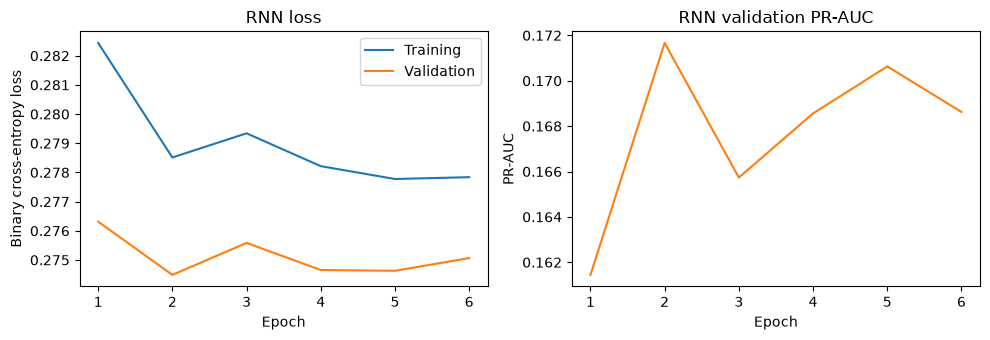

In [6]:
train_loader = make_loader(X["train"], y["train"], batch_size=512, shuffle=True)
val_loader = make_loader(X["val"], y["val"], batch_size=4096)
test_loader = make_loader(X["test"], y["test"], batch_size=4096)
loss_function = nn.BCEWithLogitsLoss()

set_seed(SEED)
rnn = SequenceClassifier("rnn").to(device)
history_rnn = train_model(rnn, train_loader, val_loader, loss_function, torch.optim.Adam(rnn.parameters(), lr=0.001), epochs=6, clip=1.0)
plot_history(history_rnn, "RNN")

## 6. Train the GRU
Identical setup; only the recurrent cell changes.

Epoch  1/6 | train loss 0.2813 | val loss 0.2743 | val PR-AUC 0.175


Epoch  2/6 | train loss 0.2763 | val loss 0.2746 | val PR-AUC 0.178


Epoch  3/6 | train loss 0.2759 | val loss 0.2732 | val PR-AUC 0.180


Epoch  4/6 | train loss 0.2756 | val loss 0.2731 | val PR-AUC 0.181


Epoch  5/6 | train loss 0.2755 | val loss 0.2733 | val PR-AUC 0.179


Epoch  6/6 | train loss 0.2752 | val loss 0.2733 | val PR-AUC 0.181


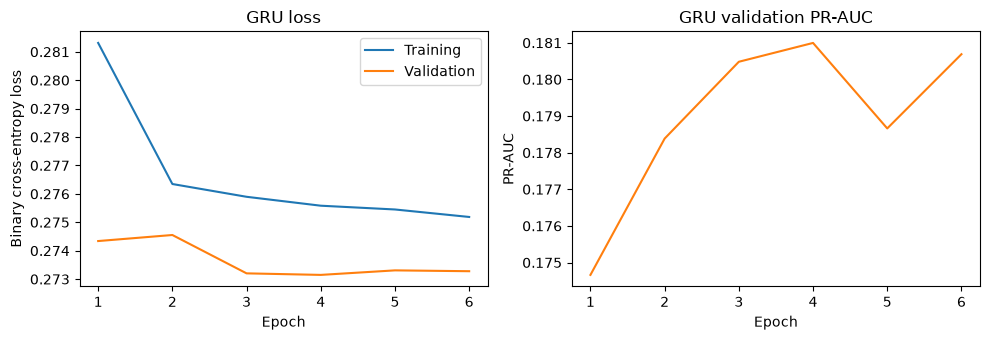

In [7]:
set_seed(SEED)
gru = SequenceClassifier("gru").to(device)
history_gru = train_model(gru, train_loader, val_loader, loss_function, torch.optim.Adam(gru.parameters(), lr=0.001), epochs=6, clip=1.0)
plot_history(history_gru, "GRU")

## 7. Test once, next to the baselines
Logistic regression is loaded from `02_baselines` (`results/logistic_regression.pt`), so all models are scored on exactly the same test visits with the same rules: cut-off chosen on validation (best F1), 95% ranges from resampling shoppers 200 times.

In [8]:
class LogisticRegression(nn.Module):
    def __init__(self, number_of_words):
        super().__init__()
        self.linear = nn.Linear(number_of_words, 1)
    def forward(self, features):
        return self.linear(features).squeeze(-1)

saved = torch.load("../results/logistic_regression.pt")
logreg = LogisticRegression(saved["config"]["number_of_words"])
logreg.load_state_dict(saved["state_dict"])
count_loader = {part: make_loader(word_counts(X[part]), y[part], batch_size=4096) for part in ("val", "test")}

scores = {
    "Industry rule": {part: (df["cart_value"].to_numpy() > 0) + 1e-6 * np.random.default_rng(SEED).uniform(size=len(df))
                      for part, df in [("val", val_df), ("test", test_df)]},
    "Logistic regression": {part: predict_proba(logreg, count_loader[part]) for part in ("val", "test")},
    "RNN": {"val": predict_proba(rnn, val_loader), "test": predict_proba(rnn, test_loader)},
    "GRU": {"val": predict_proba(gru, val_loader), "test": predict_proba(gru, test_loader)},
}
cutoffs = {name: pick_cutoff(y["val"], s["val"]) for name, s in scores.items()}

rows = []
for name, s in scores.items():
    q = quality(y["test"], s["test"], cutoffs[name])
    ci = bootstrap(test_df.assign(_s=s["test"]), lambda d, c=cutoffs[name]: {k: quality(d["label"].to_numpy(), d["_s"].to_numpy(), c)[k] for k in ("auc", "pr_auc", "f1")}, n=200, seed=SEED)
    rows.append({"model": name, **{k: round(q[k], 3) for k in ("auc", "pr_auc", "precision", "recall", "f1")},
                 "auc_95%": f"{ci['auc'][0]:.3f}–{ci['auc'][1]:.3f}", "pr_auc_95%": f"{ci['pr_auc'][0]:.3f}–{ci['pr_auc'][1]:.3f}"})
quality_table = pd.DataFrame(rows).set_index("model")
quality_table

,auc,pr_auc,precision,recall,f1,auc_95%,pr_auc_95%
model,,,,,,,
Industry rule,0.558,0.124,0.208,0.184,0.195,0.551–0.564,0.118–0.130
Logistic regression,0.676,0.157,0.161,0.370,0.224,0.670–0.682,0.148–0.165
RNN,0.679,0.163,0.169,0.323,0.222,0.673–0.685,0.153–0.170
GRU,0.682,0.172,0.168,0.355,0.228,0.676–0.688,0.162–0.181


## 8. Does order matter? (1) By visit length
Week 8 s14 says an RNN carries everything in one $H_t$, and Week 6 s31 that early clicks fade in long chains. If order helps, the sequence models should gain most over logistic regression on **longer** visits.

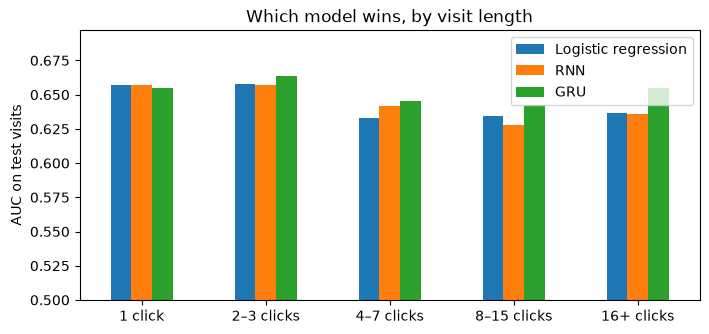

,Logistic regression,RNN,GRU,visits
1 click,0.657,0.657,0.655,35685
2–3 clicks,0.658,0.657,0.664,31725
4–7 clicks,0.633,0.642,0.645,24717
8–15 clicks,0.634,0.628,0.642,15726
16+ clicks,0.637,0.636,0.655,9678


In [9]:
length = (X["test"] != 0).sum(axis=1)
groups = pd.cut(length, [0, 2, 4, 8, 16, 65], labels=["1 click", "2–3 clicks", "4–7 clicks", "8–15 clicks", "16+ clicks"])
by_length = pd.DataFrame({
    name: [quality(y["test"][groups == g], scores[name]["test"][groups == g], 0.5)["auc"] for g in groups.categories]
    for name in ("Logistic regression", "RNN", "GRU")
}, index=groups.categories)
by_length["visits"] = pd.Series(groups).value_counts().reindex(groups.categories).to_numpy()
by_length.drop(columns="visits").plot.bar(figsize=(8, 3.5), rot=0)
plt.ylabel("AUC on test visits"); plt.ylim(0.5, None); plt.title("Which model wins, by visit length")
plt.show()
by_length.round(3)

## 9. Does order matter? (2) Shuffle the clicks
Keep each test visit's words but put the clicks in a random order (the first word, `new`/`returning`, stays first). Logistic regression gives exactly the same answer, because it only counts words. If the GRU gets worse, it was using the order.

In [10]:
rng = np.random.default_rng(SEED)
shuffled = X["test"].copy()
for row, n in enumerate(length):
    if n > 2:
        shuffled[row, 1:n] = rng.permutation(shuffled[row, 1:n])
auc_normal = quality(y["test"], scores["GRU"]["test"], 0.5)["auc"]
auc_shuffled = quality(y["test"], predict_proba(gru, make_loader(shuffled, y["test"], batch_size=4096)), 0.5)["auc"]
print(f"GRU AUC, clicks in real order:     {auc_normal:.3f}")
print(f"GRU AUC, clicks in shuffled order: {auc_shuffled:.3f}")
print(f"Logistic regression is unchanged by shuffling: {quality_table.loc['Logistic regression', 'auc']:.3f}")

GRU AUC, clicks in real order:     0.682
GRU AUC, clicks in shuffled order: 0.679
Logistic regression is unchanged by shuffling: 0.676


## 10. Money: who gets the 10% discount?
Same rules as `02_baselines`: cart abandoners only, each model gives the discount to the 60% it thinks are **least** likely to come back on their own, at most one discount per shopper per 7 days.

In [11]:
cart_val = val_df["cart_value"].to_numpy() > 0
money_rows = []
frame = test_df.copy()
frame_rule = money(frame, np.ones(len(frame), dtype=bool))
money_rows.append({"policy": "Industry rule (everyone)", "discounts": frame_rule["discounts_sent"], "€ wasted": round(frame_rule["wasted_eur"]),
                   "left without a nudge": frame_rule["left_without_nudge"]})
for name in ("Logistic regression", "RNN", "GRU"):
    cut = np.quantile(scores[name]["val"][cart_val], 0.6)
    give = scores[name]["test"] < cut
    m = money(frame, give)
    ci = bootstrap(frame.assign(_g=give), lambda d: money(d, d["_g"].to_numpy()), n=200, seed=SEED)
    money_rows.append({"policy": f"{name} (60%)", "discounts": m["discounts_sent"], "€ wasted": round(m["wasted_eur"]),
                       "€ wasted 95%": f"{ci['wasted_eur'][0]:,.0f}–{ci['wasted_eur'][1]:,.0f}", "left without a nudge": m["left_without_nudge"]})
money_table = pd.DataFrame(money_rows)
money_table

,policy,discounts,€ wasted,left without a nudge,€ wasted 95%
0,Industry rule (everyone),6622,50327,1568,NaN
1,Logistic regression (60%),4619,30202,3138,"26,380–34,426"
2,RNN (60%),4633,27802,3083,"24,201–31,124"
3,GRU (60%),4681,26703,3024,"23,276–30,738"


## 11. Save the results

In [12]:
out = pathlib.Path("../results"); (out / "scores").mkdir(parents=True, exist_ok=True)
quality_table.to_csv(out / "rnn_quality.csv")
by_length.round(3).to_csv(out / "rnn_by_length.csv")
money_table.to_csv(out / "rnn_money.csv", index=False)
for name, s in scores.items():
    np.save(out / "scores" / f"{name.lower().replace(' ', '_')}_test.npy", s["test"].astype(np.float32))
for name, model in (("rnn", rnn), ("gru", gru)):
    torch.save({"config": {"cell": name, "d": 32, "hidden": 64, "dropout": 0.2, "block_size": BLOCK_SIZE},
                "state_dict": model.state_dict(), "cutoff": cutoffs[name.upper()], "seed": SEED}, out / f"{name}.pt")
print("saved")

saved


## 12. Connect the code to the course
| Idea | Where it appears here | Course |
|---|---|---|
| Sequence $x_1, \dots, x_T$, varying length, order matters | sections 3 and 9 | Week 6 s20–s21 |
| Embedding instead of one-hot | section 4, `nn.Embedding` | Week 3 s21, Week 8 s26, workshop c15 |
| Hidden state $H_t = \phi(X_t W_{xh} + H_{t-1} W_{hh} + b_h)$ | section 4, `nn.RNN` | Week 6 s28 |
| Backpropagation through time, vanishing gradients, clipping | sections 5–6, `clip=1.0` | Week 6 s31 |
| Gated RNN (GRU) | section 6 | Week 6 s31 (named only) |
| Padding is masked out | section 4, `pack_padded_sequence` | Week 8 s20 |
| Counts throw away order | sections 8–9 | Review session, Vignette E (AK p21) |
| Keep validation and test decisions separate | section 7 | Week 3 s22 |

## Reflection questions
1. Why does `nn.RNN` reuse the same $W_{xh}$ and $W_{hh}$ at every click, and what does that mean for visits of different lengths?
2. In section 9, why can shuffling never change logistic regression's answer, but can change the GRU's?
3. If the GRU beats the plain RNN mainly on long visits, which idea from Week 6 explains that?
4. What would it mean for the Transformer if the GRU is only slightly better than logistic regression?